In [1]:
from astropy.io import fits
import glob
import numpy as np
import matplotlib.pyplot as plt
import lab2_helper_functions as lab2
from astropy.modeling.functional_models import Gaussian2D
import math

In [2]:
def real_counts(m):
    return (m/16) + 1
def load(path):
    '''
    takes folder file path as input and returns
    (# of files, 3522, 4656) shaped array of fits images
    and (# of files) shaped array of image headers
    '''
    p = path + r"\*.fit"
    l = sorted(glob.glob(p))
    a = np.zeros((len(l), 3522, 4656), np.int16)
    head = np.empty(len(l), dtype=object)
    for i in range(len(l)):
        f = fits.open(l[i])
        a[i] = real_counts(f[0].data)
        head[i] = f[0].header
        print(i, end=" ")
    return a, head

In [3]:
p = r"C:\Users\julio\OneDrive\Desktop\Observational\Lab2\Julesandxanderpicselectricboogalooidk"

In [4]:
darkHalfs, darkHalfHead = load(p + r"\Dark0.5s")

0 1 2 3 4 5 6 7 8 9 

In [5]:
dark45s, dark45Head = load(p + r"\Dark45s")

0 1 2 3 4 5 6 7 8 9 

In [6]:
biasImages, biasHead = load(p + r"\biasImages")

0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 

In [7]:
HD202240, HD202240Head = load(p + r"\HD202240")

0 1 2 3 4 5 6 7 8 9 

In [8]:
HD205435, HD205435Head = load(p + r"\HD205435")

0 1 2 3 4 5 6 7 8 9 

In [9]:
HD211458, HD211458Head = load(p + r"\HD211458")

0 1 2 3 4 5 6 7 8 9 

In [10]:
Flats, FlatsHead = load(p + r"\TwilightFlats")

0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99 

In [11]:
VegaEarly, VegaEarlyHead = load(p + r"\VegaEarly")

0 1 2 3 4 5 6 7 8 9 

In [12]:
VegaLate, VegaLateHead = load(p + r"\VegaLate")

0 1 2 3 4 5 6 7 8 9 10 

In [13]:
GoodVegaEarly, GoodVegaEarlyHead = load(p + r"\GoodVegaEarly")

0 1 2 3 4 5 6 7 8 9 

In [14]:
GoodVegaLate, GoodVegaLateHead = load(p + r"\GoodVegaLate")

0 1 2 3 4 5 6 7 8 9 

In [15]:
meanBI = np.mean(biasImages, axis=0)

In [16]:
meanDarkHalfs = np.mean(darkHalfs, axis=0) - meanBI

In [17]:
meanDark45s = np.mean(dark45s, axis=0) - meanBI

In [18]:
a = np.zeros((100))
for i in range(100):
    a[i] = i
samp = a[::10]
medianTF = np.median(Flats, axis=0)

In [19]:
normTF = np.zeros((samp.size, 3522, 4656))
z_iMed = np.zeros((samp.size))
for i in range(samp.size):
    z_iMed[i] = np.median(Flats[int(samp[i])] - meanBI)

In [20]:
for h in range (samp.size):
    normTF[h] = (Flats[int(samp[h])] - meanBI) / z_iMed[h]
    print(h, end=" ")

0 1 2 3 4 5 6 7 8 9 

In [21]:
medNormTF = np.median(normTF, axis=0)

In [22]:
diffBI = biasImages[0] - biasImages[1]
readNoise = np.std(diffBI)/(2**0.5)

In [23]:
def corrSciImg(s, d):
    return (s - d - meanBI) / medNormTF

In [24]:
meanCountsF1 = np.mean(Flats[0])
meanCountsF2 = np.mean(Flats[99])

In [25]:
print(meanCountsF1)
print(meanCountsF2)

2215.1299525466825
249.43437512806102


In [26]:
levels = np.array([2000, 1400, 800, 400, 250])

#2000
firstL1 = Flats[3] - meanBI
secondL1 = Flats[4]- meanBI

#1400
firstL2 = Flats[14]- meanBI
secondL2 = Flats[15]- meanBI
#800
firstL3 = Flats[34]- meanBI
secondL3 = Flats[35]- meanBI
#400
firstL4 = Flats[64]- meanBI
secondL4 = Flats[65]- meanBI
#250
firstL5 = Flats[98]- meanBI
secondL5 = Flats[99]- meanBI

f = np.array([firstL1, secondL1, firstL2, secondL2, firstL3, secondL3, firstL4, secondL4, firstL5, secondL5])
diffImgs = np.zeros((5, 3522, 4656), np.int16)
for i in range(5):
    f[2*i+1] = f[2*i+1] * (np.mean(f[2*i][0:50, 0:50])/np.mean(f[2*i + 1][0:50, 0:50]))
    diffImgs[i] = f[2*i] - f[2*i + 1]
    print(i, end="")

01234

In [27]:
var = np.zeros((5))
for i in range(5):
    var[i] = np.std(diffImgs[i][0:50, 0:50])**2 / (2**0.5)

In [28]:
dataPts = np.zeros((5, 2))
for i in range(5):
    dataPts[i][1] = np.mean(f[2*i])
    dataPts[i][0] = var[i]

1864.9995510180486
4140.421308656088

98.34913230728402
214.0825877330449


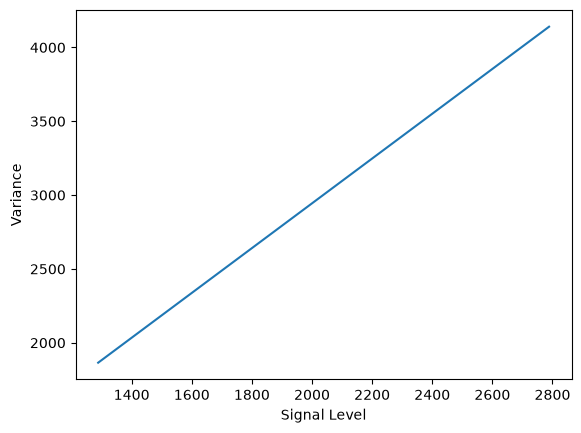

In [60]:
print(dataPts[0][1])
print(dataPts[0][0])
print()
print(dataPts[4][1])
print(dataPts[4][0])
plt.xlabel("Signal Level")
plt.ylabel("Variance")
plt.plot(dataPts[0:][1], dataPts[0:][0])
plt.savefig("var_vs_signal")

In [30]:
def leastSquares(data):
    '''
    takes array of shape (m, n) where m is the number of data pts and
    n = 0 represents y data and n = 1 represents x data

    returns coeffecients and uncertainties (alpha, beta, unc_Y, unc_B)
    '''
    def delta(arr):
        s1 = 0
        s2 = 0
        for i in range(len(arr)):
            s1 += arr[i][1]**2
            s2 += arr[i][1]
        s2 = s2**2
        return len(arr) * s1 - s2
    def alpha(arr):
        s1 = 0
        s2 = 0
        s3 = 0
        s4 = 0
        for i in range(len(arr)):
            s1 += arr[i][1]**2
            s2 += arr[i][0]
            s3 += arr[i][1]
            s4 += arr[i][1] * arr[i][0]
        return ((s1 * s2) - (s3 * s4)) / delta(arr)
    def beta(arr):
        s1 = 0
        s2 = 0
        s3 = 0
        for i in range(len(arr)):
            s1 += arr[i][0]
            s2 += arr[i][1]
            s3 += arr[i][1] * arr[i][0]
        return ((len(arr) * s3) - (s1 * s2)) / delta(arr)
    def unc_Y(arr):
        s1 = 0
        for i in range(len(arr)):
            s1 += (arr[i][0] - alpha(arr) - (beta(arr) * arr[i][1])) ** 2
        return (s1 / (len(arr) - 2)) ** 0.5
    def unc_B(arr):
        return unc_Y(arr) * ((len(arr) / delta(arr)) ** 0.5)
    return alpha(data), beta(data), unc_Y(data), unc_B(data)

In [31]:
#temp = dataPts
#for i in range(5):
#    dataPts[i][0] = temp[i][1]
#    dataPts[i][1] = temp[i][0]
#gain = beta(dataPts)
#unc_gain = unc_B(dataPts)
a, gain, u, unc_gain = leastSquares(dataPts)
print(str(gain) + " +/- " + str(unc_gain))

2.221162146350318 +/- 0.023304567584132536


In [32]:
diffBI = biasImages[0] - biasImages[1]
readNoise = np.std(diffBI)/(2**0.5)

In [33]:
def phot(fit, centroid_x, centroid_y, sigma_x, sigma_y, window, inner_rad):
    '''
    takes 2D data array (fit), center of star (centroid_x, centroid_y), width (sigma_x, sigma_y),
    size of cutout (window), and radius of inner circle within star (inner_rad

    returns point spread function for these values (model), star cutout convolved with PSF (psf_convolve),
    and total counts from within psf_convolve (psf_flux)
    '''
    f, cx, cy, sig_x, sig_y, w, r = fit, centroid_x, centroid_y, sigma_x, sigma_y, window, inner_rad
    cutout = fit[int(cx-w):int(cx+w), int(cy-w):int(cy+w)]
    xvals, yvals = np.meshgrid(np.arange(cx-w, cx+w), np.arange(cy-w, cy+w))
    xx, yy, psf = lab2.psf((cx,cy), sig_x, sig_y, w, r)

    model = psf
    psf_convolve = cutout * psf
    psf_flux = np.sum(psf_convolve)

    return model, psf_convolve, psf_flux

In [34]:
star1Coords = np.array([[int(1491.2594368248574), int(2886.7851074159485), int(2947.2942908128807-2886.7851074159485), int(3091.1716824455866-2886.7851074159485)],
[int(1534.0073431241653), int(2876.0981308411215), int(2929.990900494314-2876.0981308411215), int(3073.7049529028263-2876.0981308411215)],
[int(1573.1929238985313), int(2851.1618521665246), int(2913.2957796142687-2851.1618521665246), int(3049.3986683093267-2851.1618521665246)],
[int(1615.9408301978397), int(2811.9762713921596), int(2884.4949476093816-2811.9762713921596), int(3009.8918252349954-2811.9762713921596)],
[int(1662.25106202209), int(2779.9153416676777), int(2840.838530497974-2779.9153416676777), int(2840.838530497974-2779.9153416676777)],
[int(1708.5612938463405), int(2740.7297608933127), int(2795.9087878235623-2740.7297608933127), int(2935.3891058972504-2740.7297608933127)],
[int(1765.558502245418), int(2669.483250394465), int(2726.5984334314944-2669.483250394465), int(2870.9729238862083-2669.483250394465)],
[int(1815.4310595946108), int(2640.984646194927), int(2702.4524180701574-2640.984646194927), int(2839.572832253365-2640.984646194927)],
[int(1861.7412914188612), int(2651.671622769754), int(2719.5317727815973-2651.671622769754), int(2852.4822707639855-2651.671622769754)],
[int(1908.0515232431121), int(2683.732552494235), int(2746.0074127947823-2683.732552494235), int(2884.7913871788587-2683.732552494235)]])

In [35]:
star2Coords = np.array([[int(1612.3785046728972), int(2088.824189828863), int(2158.6966604823747-2088.824189828863), int(2285.0269016697584-2088.824189828863)],
[int(1612.3785046728972), int(2085.26186430392), int(2156.508374802767-2085.26186430392), int(2284.7520937006916-2085.26186430392)],
[int(1623.0654812477242), int(2071.012562204151), int(2142.259072702998-2071.012562204151), int(2274.0651171258646-2071.012562204151)],
[int(1626.6278067726666), int(2049.638609054497), int(2120.885119553344-2049.638609054497), int(2249.1288384512686-2049.638609054497)],
[int(1612.3785046728972), int(2031.826981429785), int(2099.51116640369-2031.826981429785), int(2227.7548853016146-2031.826981429785)],
[int(1605.2538536230127), int(2010.453028280131), int(2078.137213254036-2010.453028280131), int(2206.3809321519598-2010.453028280131)],
[int(1605.2538536230127), int(1999.766051705304), int(2063.887911154266-1999.766051705304), int(2192.1316300521908-1999.766051705304)],
[int(1601.6915280980702), int(1985.5167496055342), int(2056.763260104382-1985.5167496055342), int(2181.4446534773638-1985.5167496055342)],
[int(1607.3232388720203), int(1925.6015852297514), int(1985.0250028353157-1925.6015852297514), int(2103.8718380464434-1925.6015852297514)],
[int(1601.6915280980702), int(1921.3948901565723), int(1989.32010739405-1921.3948901565723), int(2114.2539890986964-1921.3948901565723)]])

In [36]:
star3Coords = np.array([[int(1672.938038596917), int(3000.7795242141033), int(3038.8553744748397-3000.7795242141033), int(3210.9582176533686-3000.7795242141033)],
[int(1672.938038596917), int(2993.654873164219), int(3025.207947659763-2993.654873164219), int(3206.6381260091425-2993.654873164219)],
[int(1665.8133875470326), int(2997.2171986891613), int(3044.3214218428575-2997.2171986891613), int(3203.867984137638-2997.2171986891613)],
[int(1672.938038596917), int(2943.7823158150263), int(2979.4346920032153-2943.7823158150263), int(3163.896986194283-2943.7823158150263)],
[int(1687.1873406966865), int(2847.5995266415825), int(2889.856058913029-2847.5995266415825), int(3039.162472938809-2847.5995266415825)],
[int(1708.5612938463405), int(2448.6190678480393), int(2491.020186733048-2448.6190678480393), int(2657.4838386519696-2448.6190678480393)],
[int(1694.311991746571), int(2274.0651171258646), int(2308.1109552509965-2274.0651171258646), int(2489.688758585036-2274.0651171258646)],
[int(1701.436642796456), int(2128.009770603229), int(2164.5599805459287-2128.009770603229), int(2350.4893093848823-2128.009770603229)],
[int(1712.123619371283), int(2038.95163247967), int(2068.6653658886926-2038.95163247967), int(2259.1828330406634-2038.95163247967)],
[int(1708.5612938463405), int(1978.3920985556501), int(2024.505425647625-1978.3920985556501), int(2195.57099389205-1978.3920985556501)]])

20.765167667650307


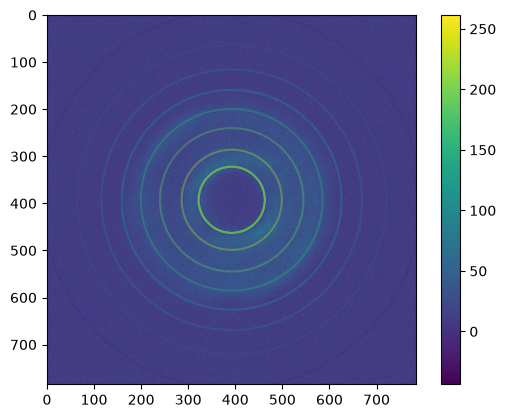

In [66]:
w = 2285.0269016697584-2088.824189828863
star = corrSciImg(HD202240[0], meanDark45s)
model, psf_convolve, psf_flux = phot(star, 1490, 2880, w, w, 2*w, 2158.6966604823747-2088.824189828863)
                                     
#plt.imshow(psf_convolve)
#plt.colorbar()
plt.contour(model, alpha=0.35)
#plt.imshow(star[int(2088.824189828863-6*w):int(2088.824189828863+6*w), int(3522-1612.3785046728972-6*w):int(3522-1612.3785046728972+6*w)], vmax=150)
plt.imshow(star[int(1490-2*w):int(1490+2*w), int(2880-2*w):int(2880+2*w)])

#plt.imshow(star)
plt.colorbar()
plt.savefig("contour")
#1490, 2880
print(psf_flux)


In [38]:

maxWindow1 = 0
maxWindow2 = 0
maxWindow3 = 0

maxStar1 = 0
maxStar2 = 0
maxStar3 = 0

for i in range(10):
    if(int(2*star1Coords[i][3]) > maxWindow1):
        maxWindow1 = 2*star1Coords[i][3]
        maxStar1 = i
    if(int(2*star2Coords[i][3]) > maxWindow2):
        maxWindow2 = 2*star2Coords[i][3]
        maxStar2 = i
    if(int(2*star3Coords[i][3]) > maxWindow3):
        maxWindow3 = 2*star3Coords[i][3]
        maxStar3 = i

print(maxWindow1)
print(maxWindow2)
print(maxWindow3)
print(maxStar1)
print(maxStar2)
print(maxStar3)

408
406
444
0
2
7


In [39]:
star1Convolved = np.zeros((10, 2*maxWindow1, 2*maxWindow1))
star1Models = np.zeros((10, 2*maxWindow1, 2*maxWindow1))
star1Flux = np.zeros((10))
star2Convolved = np.zeros((10, 2*maxWindow2, 2*maxWindow2))
star2Models = np.zeros((10, 2*maxWindow2, 2*maxWindow2))
star2Flux = np.zeros((10))
star3Convolved = np.zeros((10, 2*maxWindow3,2*maxWindow3))
star3Models = np.zeros((10, 2*maxWindow3,2*maxWindow3))
star3Flux = np.zeros((10))

In [40]:
for i in range(10):
    star1Models[i], star1Convolved[i], star1Flux[i] = phot(HD202240[i], star1Coords[i][0], star1Coords[i][1], star1Coords[i][3], star1Coords[i][3], maxWindow1, star1Coords[i][2])
    star2Models[i], star2Convolved[i], star2Flux[i] = phot(HD205435[i], star2Coords[i][0], star2Coords[i][1], star2Coords[i][3], star2Coords[i][3], maxWindow2, star2Coords[i][2])
    star3Models[i], star3Convolved[i], star3Flux[i] = phot(HD211458[i], star3Coords[i][0], star3Coords[i][1], star3Coords[i][3], star3Coords[i][3], maxWindow3, star3Coords[i][2])

In [41]:
Nsky = np.zeros((3, 10))

for i in range(10):
    a, aperture1, b = phot(HD202240[i], maxWindow1, maxWindow1, star1Coords[i][3], star1Coords[i][3], maxWindow1, star1Coords[i][2])
    a, aperture2, b = phot(HD205435[i], maxWindow2, maxWindow2, star2Coords[i][3], star2Coords[i][3], maxWindow2, star2Coords[i][2])
    a, aperture3, b = phot(HD211458[i], maxWindow3, maxWindow3, star3Coords[i][3], star3Coords[i][3], maxWindow3, star3Coords[i][2])
    Nsky[0][i] = np.median(aperture1)
    Nsky[1][i] = np.median(aperture2)
    Nsky[2][i] = np.median(aperture3)

In [42]:
Nnet = np.zeros((3, 10))

for i in range(10):
    Nnet[0][i] = np.sum(star1Convolved[i] - Nsky[0][i])
    Nnet[1][i] = np.sum(star2Convolved[i] - Nsky[1][i])
    Nnet[2][i] = np.sum(star3Convolved[i] - Nsky[2][i])

In [43]:
def SNR(starNum, imgNum, width):
    '''
    Given a star and image of that star, as well as a width (dist from star center to edge of aperture)
    returns signal to noise ratio, and total pixels in aperture
    '''
    
    pix = (2*width)**2
    SNR = Nnet[starNum][imgNum] / np.sqrt(gain*Nnet[starNum][imgNum] + pix*gain*Nsky[starNum][imgNum] + pix*(readNoise**2))
    return SNR, pix

In [44]:
width1 = int(maxWindow1 / 2)
width2 = int(maxWindow2 / 2)
width3 = int(maxWindow3 / 2)


#widths = np.array([[width1/2, 3*width1/4, width1, 5*width1/4, 3*width1/2, 2*width1, 3*width1, 4*width1],
#                   [width2/2, 3*width2/4, width2, 5*width2/4, 3*width2/2, 2*width2, 3*width2, 4*width2],
#                   [width3/2, 3*width3/4, width3, 5*width3/4, 3*width3/2, 2*width3, 3*width3, 4*width3]])
widths = np.array([np.arange(width1, 3*width1)[::52], np.arange(width2, 3*width2)[::52], np.arange(width3, 3*width3)[::56]])
widths = widths.astype(int)
#w = len(np.arange(width2, 3*width2)[::52])
#print(w)
nPixels = np.zeros((8, 3, 10))
flux = np.zeros((8, 3, 10))
SNRvals = np.zeros((8, 3, 10))
stars = np.array([HD202240, HD205435, HD211458])
coords = np.array([star1Coords, star2Coords, star3Coords])

for i in range(8):
    for j in range(3):
        for k in range(10):
            SNRvals[i][j][k], nPixels[i][j][k] = SNR(j, k, widths[j][i])
            a, b, flux[i][j][k] = phot(stars[j][k], coords[j][k][0], coords[j][k][1], coords[j][k][3], coords[j][k][3], widths[j][i], coords[j][k][2])

[ 197136.  309136.  446224.  608400.  795664. 1008016. 1245456. 1507984.]
[0.05757046 0.04597466 0.03826684 0.03277238 0.02865761 0.02546083
 0.02290568 0.0208166 ]
190.59106288685365


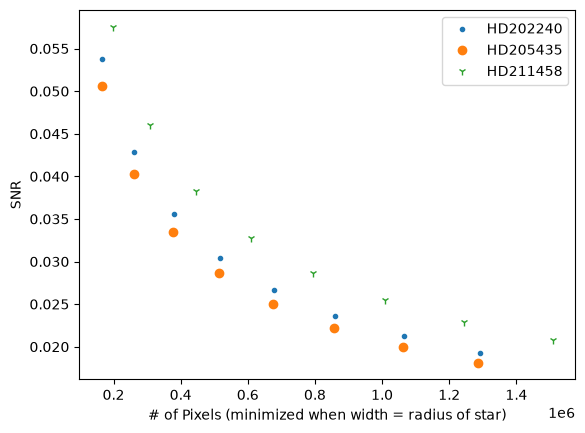

In [45]:
x0 = nPixels[0:, 0, maxStar1]
y0 = SNRvals[0:, 0, maxStar1]

x1 = nPixels[0:, 1, maxStar2]
y1 = SNRvals[0:, 1, maxStar2]

x2 = nPixels[0:, 2, maxStar3]
y2 = SNRvals[0:, 2, maxStar3]

print(x2)
print(y2)
print(flux[0][0][0])

plt.plot(x0, y0, ".", label="HD202240")
plt.plot(x1, y1, "o", label="HD205435")
plt.plot(x2, y2, "1", label="HD211458")
plt.xlabel("# of Pixels (minimized when width = radius of star)")
plt.ylabel("SNR")
plt.legend()
plt.savefig("idealAperture")

In [46]:
def instMag(starNum, imgNum):
    mag = -2.5*np.log10(Nnet[starNum, imgNum]/45)
    unc = mag / SNRvals[0][starNum][imgNum]
    return mag, unc

In [47]:
print(instMag(0, maxStar1))
print(instMag(1, maxStar2))
print(instMag(2, maxStar3))

(np.float64(-0.038619580176316226), np.float64(-0.7189018946284467))
(np.float64(0.03135509648240066), np.float64(0.6194764279447146))
(np.float64(-0.2055706269444552), np.float64(-3.5707655911498426))


In [48]:
print(GoodVegaEarlyHead[0])

SIMPLE  =                    T                                                  BITPIX  =                   16 /8 unsigned int, 16 & 32 int, -32 & -64 real     NAXIS   =                    2 /number of axes                                  NAXIS1  =                 4656 /fastest changing axis                           NAXIS2  =                 3522 /next to fastest changing axis                   BSCALE  =   1.0000000000000000 /physical = BZERO + BSCALE*array_value           BZERO   =   32768.000000000000 /physical = BZERO + BSCALE*array_value           DATE-OBS= '2026-09-22T03:21:55' /YYYY-MM-DDThh:mm:ss observation start, UT      EXPTIME =   5.0000000000000000 /Exposure time in seconds                        EXPOSURE=   5.0000000000000000 /Exposure time in seconds                        SET-TEMP=  -20.000000000000000 /CCD temperature setpoint in C                   CCD-TEMP=  -20.000000000000000 /CCD temperature at start of exposure in C       XPIXSZ  =   3.7999999999999998 /Pixel Wi

In [49]:
print(GoodVegaLateHead[0])

SIMPLE  =                    T                                                  BITPIX  =                   16 /8 unsigned int, 16 & 32 int, -32 & -64 real     NAXIS   =                    2 /number of axes                                  NAXIS1  =                 4656 /fastest changing axis                           NAXIS2  =                 3522 /next to fastest changing axis                   BSCALE  =   1.0000000000000000 /physical = BZERO + BSCALE*array_value           BZERO   =   32768.000000000000 /physical = BZERO + BSCALE*array_value           DATE-OBS= '2026-09-22T06:16:46' /YYYY-MM-DDThh:mm:ss observation start, UT      EXPTIME =   5.0000000000000000 /Exposure time in seconds                        EXPOSURE=   5.0000000000000000 /Exposure time in seconds                        SET-TEMP=  -20.000000000000000 /CCD temperature setpoint in C                   CCD-TEMP=  -20.000000000000000 /CCD temperature at start of exposure in C       XPIXSZ  =   3.7999999999999998 /Pixel Wi

In [50]:
#vega alt at time 1: 78 04 54.1
z1 = np.radians(78 + 4/60 + 54.1/3600)
#vega alt at time 2: 65 31 57.3
z2 = np.radians(65 + 31/60 + 57.3/3600)
#exposure time
t = 5

In [51]:
vega1Coords = np.array([int(2064.7938463405753), int(2676.60790144435), int(2881.6202433887734-2676.60790144435), int(3397.8120329274107-2676.60790144435)])
vega2Coords = np.array([int(2577.7687219322734), int(2580.425112270907), int(2799.3961093724765-2580.425112270907), int(3356.2080734307547-2580.425112270907)])

In [52]:
a, vegAp1, b = phot(GoodVegaEarly[0], vega1Coords[3], vega1Coords[3], vega1Coords[3], vega1Coords[3], vega1Coords[3], vega1Coords[2])
VegNsky1 = np.median(vegAp1)
a, vegAp2, b = phot(GoodVegaLate[0], vega2Coords[3], vega2Coords[3], vega2Coords[3], vega2Coords[3], vega2Coords[3], vega2Coords[2])
VegNsky2 = np.median(vegAp2)

a, Vega1Conv, b = phot(GoodVegaEarly[0], vega1Coords[0], vega1Coords[1], vega1Coords[3], vega1Coords[3], vega1Coords[3], vega1Coords[2])
a, Vega2Conv, b = phot(GoodVegaLate[0], vega2Coords[0], vega2Coords[1], vega2Coords[3], vega2Coords[3], vega2Coords[3], vega2Coords[2])

NnetVegaEarly = np.sum(Vega1Conv - VegNsky1)
NnetVegaLate = np.sum(Vega2Conv - VegNsky2)

#mag of vega: +0.026 (−0.02, +0.07)
vegaKnownMag = 0.026

off1 = vegaKnownMag + 2.5*np.log10(NnetVegaEarly/t)
off2 = vegaKnownMag + 2.5*np.log10(NnetVegaLate/t)

secZ1 = 1/np.cos(z1)
secZ2 = 1/np.cos(z2)

k = (off1 - off2) / (secZ1 - secZ2)
ZP = off1 - k*secZ1

print(k)
print(ZP)
print(k/np.cos(60))

0.12296242057545453
5.774271808738614
-0.12910619983555377


In [53]:
def calibrate(starNum, imgNum, z):
    val = -2.5*np.log10(Nnet[starNum][imgNum]/45) + ZP + k/np.cos(z)
    unc =(val - ZP - k/np.cos(z))/SNRvals[0][starNum][imgNum]
    return val, unc

In [54]:
print(HD202240Head[0])

SIMPLE  =                    T                                                  BITPIX  =                   16 /8 unsigned int, 16 & 32 int, -32 & -64 real     NAXIS   =                    2 /number of axes                                  NAXIS1  =                 4656 /fastest changing axis                           NAXIS2  =                 3522 /next to fastest changing axis                   BSCALE  =   1.0000000000000000 /physical = BZERO + BSCALE*array_value           BZERO   =   32768.000000000000 /physical = BZERO + BSCALE*array_value           DATE-OBS= '2026-10-15T02:45:31' /YYYY-MM-DDThh:mm:ss observation start, UT      EXPTIME =   45.000000000000000 /Exposure time in seconds                        EXPOSURE=   45.000000000000000 /Exposure time in seconds                        SET-TEMP=  -20.000000000000000 /CCD temperature setpoint in C                   CCD-TEMP=   13.000000000000000 /CCD temperature at start of exposure in C       XPIXSZ  =   3.7999999999999998 /Pixel Wi

In [55]:
print(HD205435Head[2])

SIMPLE  =                    T                                                  BITPIX  =                   16 /8 unsigned int, 16 & 32 int, -32 & -64 real     NAXIS   =                    2 /number of axes                                  NAXIS1  =                 4656 /fastest changing axis                           NAXIS2  =                 3522 /next to fastest changing axis                   BSCALE  =   1.0000000000000000 /physical = BZERO + BSCALE*array_value           BZERO   =   32768.000000000000 /physical = BZERO + BSCALE*array_value           DATE-OBS= '2026-10-15T02:12:47' /YYYY-MM-DDThh:mm:ss observation start, UT      EXPTIME =   45.000000000000000 /Exposure time in seconds                        EXPOSURE=   45.000000000000000 /Exposure time in seconds                        SET-TEMP=  -20.000000000000000 /CCD temperature setpoint in C                   CCD-TEMP=   13.400000000000000 /CCD temperature at start of exposure in C       XPIXSZ  =   3.7999999999999998 /Pixel Wi

In [56]:
print(HD211458Head[7])

SIMPLE  =                    T                                                  BITPIX  =                   16 /8 unsigned int, 16 & 32 int, -32 & -64 real     NAXIS   =                    2 /number of axes                                  NAXIS1  =                 4656 /fastest changing axis                           NAXIS2  =                 3522 /next to fastest changing axis                   BSCALE  =   1.0000000000000000 /physical = BZERO + BSCALE*array_value           BZERO   =   32768.000000000000 /physical = BZERO + BSCALE*array_value           DATE-OBS= '2026-10-15T03:12:53' /YYYY-MM-DDThh:mm:ss observation start, UT      EXPTIME =   45.000000000000000 /Exposure time in seconds                        EXPOSURE=   45.000000000000000 /Exposure time in seconds                        SET-TEMP=  -20.000000000000000 /CCD temperature setpoint in C                   CCD-TEMP=   12.699999999999999 /CCD temperature at start of exposure in C       XPIXSZ  =   3.7999999999999998 /Pixel Wi

In [57]:
#HD202240 alt: 60 29 32.3
#HD205435 alt: 55 22 32.3
#HD211458 alt: 57 34 34.4
zStar1 = np.radians(60 + 29/60 + 32.3/3600)
zStar2 = np.radians(55 + 22/60 + 32.3/3600)
zStar3 = np.radians(57 + 34/60 + 34.4/3600)

corrMagStar1, corrUnc1 = calibrate(0, maxStar1, zStar1)
corrMagStar2, corrUnc2 = calibrate(1, maxStar2, zStar2)
corrMagStar3, corrUnc3 = calibrate(2, maxStar3, zStar3)

print(str(corrMagStar1) + " +/- " + str(corrUnc1))
print(str(corrMagStar2) + " +/- " + str(corrUnc2))
print(str(corrMagStar3) + " +/- " + str(corrUnc3))

5.985301619595338 +/- -0.718901894628457
6.022036248964796 +/- 0.6194764279447142
5.798032889872926 +/- -3.5707655911498435


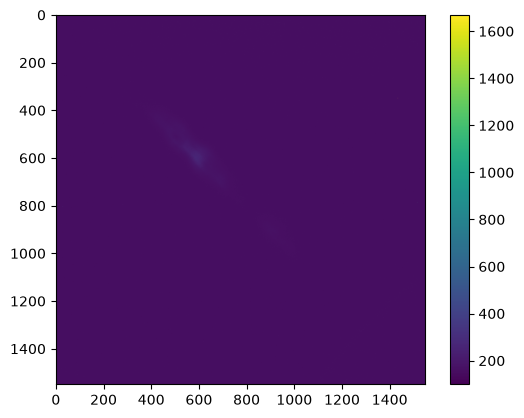

In [67]:
#plt.imshow(GoodVegaEarly[0][0:2*vega1Coords[3],0:2*vega1Coords[3]])
plt.imshow(GoodVegaLate[0][0:2*vega2Coords[3],0:2*vega2Coords[3]])
plt.colorbar()

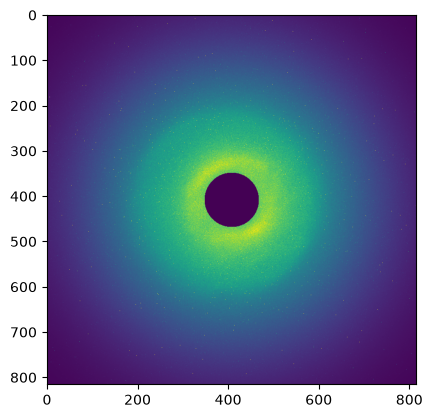

In [75]:
plt.imshow(star1Convolved[0], vmax=0.001)
plt.savefig("cool")

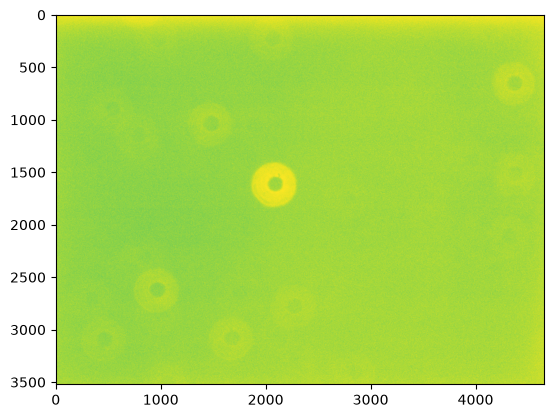

In [87]:
plt.imshow(HD205435[0], vmax=180)
plt.savefig("fullImg")

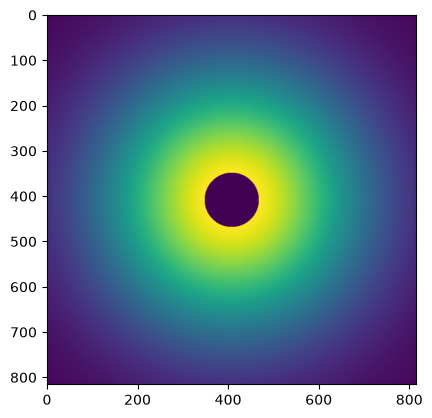

In [90]:
plt.imshow(star1Models[0])
plt.savefig("psf")